# Fine-tuning de un Transformer para el asistente

En el notebook 04 el asistente aprendió a entender al operador con **TF-IDF + regresión logística**: cuenta trozos de palabras, pero no entiende el contexto. Aquí damos el paso que conecta con el diagrama de la arquitectura **Transformer**: tomamos un modelo de lenguaje ya preentrenado en español y lo **ajustamos (fine-tuning)** a nuestras dos tareas:

- **Intención** de la pregunta: `que_hago`, `por_que`, `cuanto`, `seguir`, `prevenir`, `planta`, `fuera`.
- **Falla** mencionada: `ninguna`, `HDF`, `PWF_high`, `PWF_low`, `OSF`, `TWF`.

Se usan **los mismos datos y las mismas particiones** que el notebook 04 (`assistant_data.build(seed=0)`), así la comparación es justa.

## ¿Qué parte del diagrama se entrena?

El diagrama del Transformer tiene dos bloques: el **encoder** (izquierda) y el **decoder** (derecha). Para clasificar texto solo hace falta el **encoder**:

1. **Embeddings + codificación posicional**: cada sub-palabra de la pregunta (*"se calienta"* → `se`, `calienta`) se convierte en un vector y se le suma su posición.
2. **Bloques del encoder** (×6 en DistilBERT): cada uno tiene **atención multi-cabeza** (cada palabra mira a las demás; así *"calienta"* se relaciona con *"por qué"* o con *"qué hago"*) seguida de una red **feed-forward**, ambas con *Add & Norm*.
3. A la salida, el vector del token especial **[CLS]** resume toda la pregunta.

Lo que añadimos nosotros son **dos cabezas lineales + softmax** sobre ese vector [CLS] (una para la intención y otra para la falla). En el fine-tuning se entrenan **las cabezas y también todos los pesos del encoder** con nuestras preguntas. El **decoder no se usa**: sirve para generar texto (traducir, redactar), y aquí solo clasificamos.

**Modelo elegido:** `dccuchile/distilbert-base-spanish-uncased` (DistilBETO): versión destilada de BETO, preentrenado en español por la Universidad de Chile. Tiene 6 capas en lugar de 12, así que entrena en CPU en un tiempo razonable.

In [1]:
from pathlib import Path
import sys, json, importlib
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
TT = importlib.import_module("scripts.train_transformer")

# True: entrena ahora (CPU, unos 50 min). False: usa el último resultado guardado en reports/.
ENTRENAR = False
EPOCAS = 4

if ENTRENAR:
    res, bundle = TT.run(epochs=EPOCAS)
else:
    res = json.loads(TT.REPORT.read_text(encoding="utf-8"))
print("Mejor época:", res["best_epoch"], "| umbral de rechazo:", res["reject_threshold"], "| tiempo:", res["train_seconds"], "s")

C:\Users\crisa\OneDrive\Documents\IA\deteccion-fallas-maquinaria-main\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Mejor época: 1 | umbral de rechazo: 0.0 | tiempo: 2747 s


## Curva de pérdida y F1 por época

La **pérdida** es la entropía cruzada sumada de las dos tareas. Si la de validación deja de bajar mientras la de entrenamiento sigue bajando, el modelo empieza a memorizar (sobreajuste): por eso nos quedamos con la **mejor época según validación**.

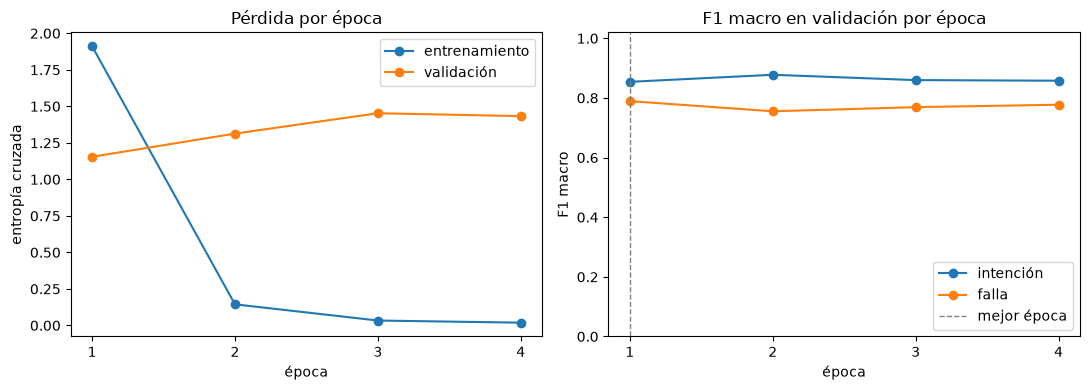

In [2]:
import matplotlib.pyplot as plt
h = res["history"]; ep = [r["epoch"] for r in h]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ep, [r["train_loss"] for r in h], "o-", label="entrenamiento")
ax[0].plot(ep, [r["val_loss"] for r in h], "o-", label="validación")
ax[0].set(title="Pérdida por época", xlabel="época", ylabel="entropía cruzada"); ax[0].legend()
ax[1].plot(ep, [r["val_intent_macro_f1"] for r in h], "o-", label="intención")
ax[1].plot(ep, [r["val_cause_macro_f1"] for r in h], "o-", label="falla")
ax[1].axvline(res["best_epoch"], color="gray", ls="--", lw=1, label="mejor época")
ax[1].set(title="F1 macro en validación por época", xlabel="época", ylabel="F1 macro", ylim=(0, 1.02)); ax[1].legend()
for a in ax: a.set_xticks(ep)
plt.tight_layout(); plt.show()

## Comparación con el TF-IDF y la línea base

Se evalúa una sola vez en **prueba** (frases y marcos de pregunta nunca vistos) y en el conjunto **natural** (preguntas escritas a mano, fuera de las plantillas).

In [3]:
import pandas as pd
names = {"linea_base_similitud": "Línea base (sin entrenar)", "tfidf_logistica": "TF-IDF + regresión logística", "transformer": "Transformer (fine-tuning)"}
rows = []
for split, label in (("test_plantillas_no_vistas", "Prueba"), ("natural_a_mano", "Natural")):
    for k, n in names.items():
        m = res[split][k]
        rows.append({"conjunto": label, "modelo": n, "intención acc": m["intent_accuracy"], "intención F1": m["intent_macro_f1"],
                     "falla acc": m["cause_accuracy"], "falla F1": m["cause_macro_f1"]})
tabla = pd.DataFrame(rows).set_index(["conjunto", "modelo"])
tabla.style.format("{:.0%}")

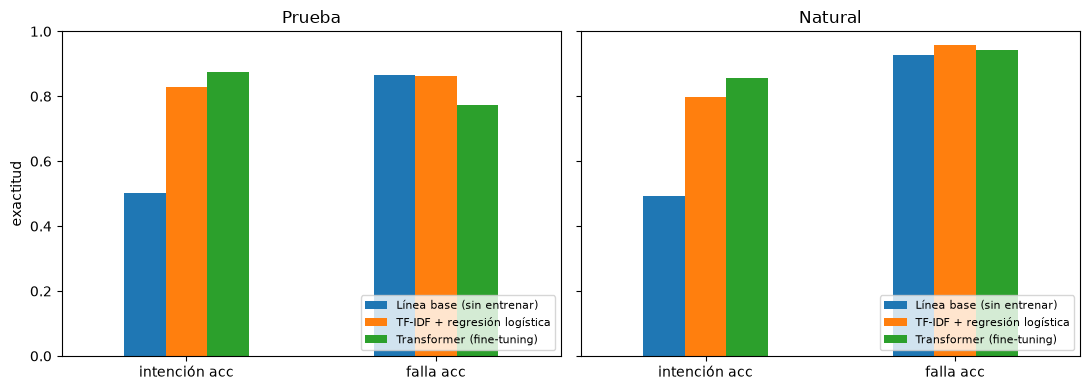

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, split, label in ((ax[0], "test_plantillas_no_vistas", "Prueba"), (ax[1], "natural_a_mano", "Natural")):
    t = tabla.loc[label][["intención acc", "falla acc"]]
    t.T.plot.bar(ax=a, rot=0); a.set(title=label, ylim=(0, 1), ylabel="exactitud"); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

Errores del Transformer en el conjunto natural:

In [5]:
errs = res["natural_a_mano"]["errores_transformer"]
print(len(errs), "errores de", 69)
for e in errs[:10]:
    print(f"- {e['texto']!r}\n    esperado: {e['esperado'][0]}/{e['esperado'][1]}   predicho: {e['predicho'][0]}/{e['predicho'][1]}")

13 errores de 69
- 'el refrigerante no está enfriando como antes'
    esperado: por_que/HDF   predicho: que_hago/HDF
- '¿se podrá terminar el pedido con esta herramienta tan vieja?'
    esperado: seguir/TWF   predicho: que_hago/TWF
- '¿hay riesgo de que se me rompa la fresa?'
    esperado: cuanto/TWF   predicho: prevenir/ninguna
- 'auxilio, la 12 está en rojo'
    esperado: que_hago/ninguna   predicho: planta/ninguna
- 'la potencia se pasó del límite, ¿es grave?'
    esperado: cuanto/PWF_high   predicho: cuanto/PWF_low
- 'está muy caliente la temperatura del proceso'
    esperado: por_que/HDF   predicho: que_hago/HDF
- 'resumen del turno por favor'
    esperado: planta/ninguna   predicho: fuera/ninguna
- 'la potencia está altísima, ¿la apago?'
    esperado: seguir/PWF_high   predicho: que_hago/PWF_high
- '¿podrías explicarme qué es un gradiente descendente?'
    esperado: fuera/ninguna   predicho: por_que/ninguna
- '¿qué puede estar causando tanta potencia?'
    esperado: por_que/PWF_h

In [6]:
# Prueba rápida con preguntas nuevas (solo si se entrenó en esta sesión)
if ENTRENAR:
    preguntas = ["oye, ¿por qué se está calentando tanto la fresadora 3?", "¿cuánto le queda a la herramienta antes de romperse?",
                 "¿cómo está toda la planta hoy?", "¿quién ganó el partido ayer?"]
    for q, (i, c) in zip(preguntas, zip(*bundle.predict(preguntas))):
        print(f"{q!r:58} -> {i:9} {c}")

In [7]:
# Versión comprimida (ONNX int8) que usa la aplicación web
onnx = json.loads((ROOT / "reports/asistente_transformer_onnx.json").read_text())
print("Tamaño:", round(onnx["bytes_onnx_int8"] / 2**20), "MB")
pd.DataFrame({k: onnx[k] for k in ("test_plantillas_no_vistas", "natural_a_mano")}).T.style.format("{:.0%}")

Tamaño: 64 MB


,intent_accuracy,intent_macro_f1,cause_accuracy,cause_macro_f1
test_plantillas_no_vistas,87%,86%,77%,69%
natural_a_mano,80%,80%,96%,90%


## Conclusiones y despliegue

- El Transformer llega con **conocimiento previo del español** (preentrenamiento) y solo lo ajustamos: por eso entiende variantes y faltas de ortografía que el TF-IDF solo ve como trozos de letras.
- La comparación usa exactamente los mismos datos, particiones y protocolo (época y umbral elegidos con validación; prueba y natural evaluados una vez).
- **Despliegue en la aplicación:** el modelo de PyTorch pesa unos 250 MB y no cabe con PyTorch en Render gratuito (512 MB de RAM). Por eso `scripts/export_transformer_onnx.py` lo exporta a **ONNX cuantizado a 8 bits (67 MB)**, que corre con ONNX Runtime sin PyTorch (unos 270 MB de RAM con toda la aplicación, ~5 ms por pregunta). El asistente de la web usa este Transformer y, si no puede cargarlo, vuelve automáticamente al **TF-IDF de respaldo**. Sus métricas tras la compresión están en `reports/asistente_transformer_onnx.json`.